# Experimento 005 — simplificación y validación de F1 macro
Reproducir entrenamiento desde la raíz con `.venv/bin/python -m src.experimento_005`; este comando regenera artefactos de 005, por lo que se debe conservar una copia si se necesita su historial. Generar este notebook con `.venv/bin/python src/informe_005.py`. No se vuelven a ejecutar los experimentos anteriores.

La auditoría previa está en `reports/revision_auditor_004_para_005.md`. La regla y las seis alternativas se registraron antes de ejecutar en `reports/plan_005.json`.

In [1]:
from pathlib import Path
import os,json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
if not Path('reports/registro_005.json').exists():os.chdir('..')
r=json.loads(Path('reports/registro_005.json').read_text())
display(Markdown(Path('reports/resumen_005.md').read_text()))
cv=pd.read_csv('reports/resultados_cv_005.csv')
display(cv[['name','mean_train_score','mean_test_score','std_test_score','f1_gap','selected']])
display(pd.read_csv('reports/cv_005_anidada.csv'))

# Versión 005: simplificación de 004 con F1 macro

Configuración seleccionada: `{'name': 'ng1_nochar', 'max_ngram': 1, 'min_df': 3, 'char_weight': 0.0, 'max_features': 160000}`. Clasificador LinearSVC C=2.

| F1 macro | Referencia 004 | Procedimiento 005 |
|---|---:|---:|
| CV usada para selección | 0.851422 | 0.874163 |
| Brecha train-CV | 0.148529 | 0.125293 |
| OOF externa agrupada | 0.850578 | 0.873382 |

F1 de entrenamiento de la selección 005: 0.999456. F1 medio de folds externos: 0.873373 ± 0.004074. La media de folds y F1 de predicciones agrupadas no son la misma operación.

## Interpretación

El auditor mejoró 004 quitando trigramas de cláusulas. Esta ronda contrasta más simplificación, frecuencia mínima y ausencia de caracteres con un presupuesto previo de seis configuraciones. Selección exclusivamente por F1 macro y control de brecha: F1 macro exclusivamente; exigir brecha <= brecha de ref004 +0.002; entre elegibles a <=0.003 del mejor F1, menor brecha; desempate mayor F1. Si no mejora F1 de ref004 en >=0.002, conservar referencia.

La evaluación externa repite la selección dentro del entrenamiento de cada fold: no selecciona directamente por los scores externos como hizo 004. Desarrollo ya fue examinado en rondas anteriores, por lo que esta separación no equivale a una prueba nueva. La referencia 004 también fue elegida históricamente con estos folds; no se oculta esa adaptación.

La meta 0,90 no se alcanza en la estimación externa local. Un F1 mayor no elimina el sobreajuste. La brecha persiste y las familias de textos o plantillas podrían inducir dependencia no capturada por los grupos de minúsculas/espacios.

La antigua prueba local se excluyó. Tras cerrar selección, todo train se usa para producción; eval solo para predecir. No se consultó Kaggle. El público conocido de 004 es 0,86111; no es el resultado de esta versión ni se usó para ajustar parámetros. El público 005 está pendiente.

## Artefactos y verificaciones

CSV nuevo creado: True. Archivo: submissions/submission_005.csv. Modelo: models/modelo_005.joblib. El Pipeline requiere src/features_004.py.

Se verificaron matrices dispersas, grupos disjuntos, convergencia de los nuevos SVM, conservación de datos y artefactos anteriores. Si se generó CSV, se verificaron esquema id,answer, cantidad, IDs únicos, orden de sample_submission, etiquetas, ausencia de vacíos, lectura de ida y vuelta y predicciones tras recarga. Duración total medida del experimento: 644.2 segundos.

La numeración 005 es versión de archivo. Los envíos reales reportados por el usuario son 002, 003 y 004; esta sería la siguiente carga manual, salvo otros envíos no comunicados.


,name,mean_train_score,mean_test_score,std_test_score,f1_gap,selected
0,ref004,0.999951,0.851422,0.002511,0.148529,False
1,ng1,0.999852,0.873034,0.004937,0.126817,False
2,ng2_min10,0.999703,0.854618,0.002872,0.145086,False
3,ng2_cap30000,0.999456,0.853841,0.003140,0.145615,False
4,ng1_nochar,0.999456,0.874163,0.003593,0.125293,True
5,ng2_nochar,0.999901,0.855040,0.002351,0.144861,False


,fold,selected,f1_train,f1_external,reference004_external
0,0,ng1_nochar,0.999555,0.874377,0.851122
1,1,ng1_nochar,0.999703,0.867958,0.846029
2,2,ng1_nochar,0.999110,0.877785,0.854585


## Diagnóstico externo
Estas métricas usan predicciones fuera del fold de entrenamiento. Los parámetros se escogen dentro de cada entrenamiento externo. No se reajusta la configuración tras observar estas matrices. Precisión y recall son diagnósticos; el criterio de selección sigue siendo F1 macro.

,precision,recall,f1-score,support
negativo,0.817805,0.820475,0.819138,3370.0
neutral,0.978731,0.997204,0.987881,2861.0
positivo,0.821126,0.805283,0.813128,3369.0
macro avg,0.872554,0.874321,0.873382,9600.0
weighted avg,0.866930,0.867812,0.867318,9600.0


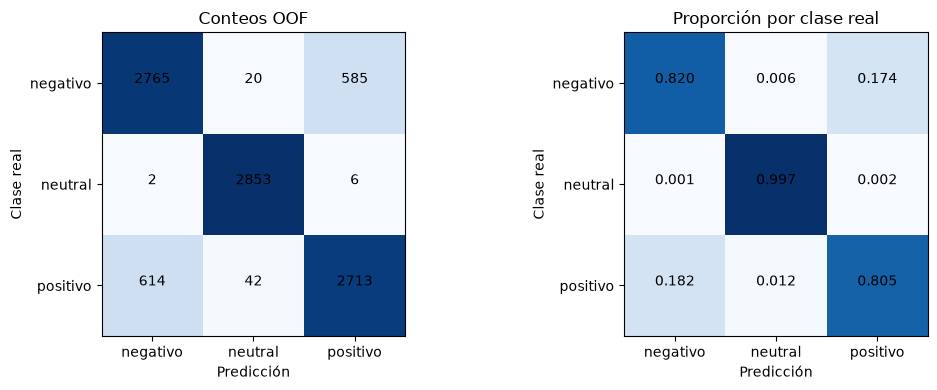

**ID 11529; real negativo; predicción positivo.** Compré esta máquina el mes pasado y la armé yo solo en el garaje. El ensamblaje cumple de sobra, las piezas venían bien marcadas y no faltó ningún tornillo. Eso sí, no le recomiendo la velocidad a nadie, la probé con ropa gruesa y no dio el ancho. Todavía no me decido si me la quedo o la devuelvo.

**ID 7600; real negativo; predicción positivo.** Lo pedi a mediados de mes y llego en unos cuatro dias a mi casa. La verdad, no tengo ni una sola queja del sonido. Ya lo habia usado un par de semanas en el cuarto antes de probar el resto. De paso, el motor me decepciono de lo lindo.

**ID 4058; real negativo; predicción neutral.** Lo compre a comienzos de ano para uso diario en casa. Desde hace meses, lo pruebo casi todos los dias, sobre todo en las mananas antes de salir. El motor se dano antes de lo que esperaba, apenas cumplidos los primeros meses de uso. Todavia guardo la caja por si hay que enviarlo a garantia.

**ID 11931; real negativo; predicción positivo.** Lo pedí un martes por internet y llegó al cuarto día. La resolución respondió tal como esperaba, la uso sobre todo en el escritorio de la casa por las tardes. Eso sí, terminé harto del menú de ajustes. Para gustos, colores.

**ID 9322; real negativo; predicción positivo.** La pedí por la app un domingo por la tarde, llegó como en tres días a la casa. Ya con un tiempo de uso, la estoy probando a fondo estos días. De paso, el servicio luce agradable en mi experiencia, la verdad. Pero el diseño se sintió poco fiable para lo que necesitaba.

In [2]:
display(pd.DataFrame(r['per_class']).T)
a=np.asarray(r['confusion'])
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,values,title in [(axs[0],a,'Conteos OOF'),(axs[1],a/a.sum(axis=1,keepdims=True),'Proporción por clase real')]:
 ax.imshow(values,cmap='Blues')
 ax.set(xticks=range(3),yticks=range(3),xticklabels=r['labels'],yticklabels=r['labels'],xlabel='Predicción',ylabel='Clase real',title=title)
 for i in range(3):
  for j in range(3):ax.text(j,i,str(values[i,j]) if title=='Conteos OOF' else f'{values[i,j]:.3f}',ha='center')
plt.tight_layout();plt.savefig('reports/confusion_005.png',dpi=160);plt.show()
oof=pd.read_csv('reports/predicciones_oof_005.csv',dtype={'id':str})
train=pd.read_csv('data/train.csv',dtype={'id':str})
errors=oof[oof.label.ne(oof.prediction)].merge(train[['id','text']],on='id',validate='one_to_one')
for _,x in errors.sample(min(5,len(errors)),random_state=42).iterrows():
 display(Markdown(f'**ID {x.id}; real {x.label}; predicción {x.prediction}.** '+x.text))

## Interpretación de errores y límites
La selección de ejemplos es reproducible y posterior al cierre de parámetros. Leer una reseña con valoraciones contrapuestas no demuestra cuál expresión causó un fallo; evitar explicaciones causales no verificadas. La comparación emparejada sirve para describir diferencias, pero las decisiones históricas sobre este mismo desarrollo limitan la independencia de la evaluación. Un score público puede fluctuar por la composición de su subconjunto.

La menor complejidad se contrasta junto al F1 de validación; no se presupone que menor vocabulario o mayor regularización siempre sean mejores. Nunca se usan los IDs como características ni respuestas de sample_submission como etiquetas. Los originales 001–004 se conservan.

In [3]:
display(r.get('checks',{}))
display(r.get('artifacts_sha256',{}))
print('Artefactos anteriores intactos:',r['old_artifacts_unchanged'])
if r['submission_created']:
 s=pd.read_csv('submissions/submission_005.csv',dtype={'id':str});display(s.head());display(s.answer.value_counts())
else: print(r['reason'])

{'ids_order_schema_labels': True,
 'roundtrip': True,
 'reload_predictions': True,
 'disjoint_groups': True}

{'models/modelo_005.joblib': '07a2f4287929027a65be9fb85b6b3285ae7d641b61614a486d8e2ba41e810c8e',
 'submissions/submission_005.csv': 'e36abffb97db94540693a1077cb02e77129a8d7e0055a94d9c636da1cf51ed7a'}

Artefactos anteriores intactos: True


,id,answer
0,0,neutral
1,1,positivo
2,2,neutral
3,3,neutral
4,4,neutral


answer
positivo    1097
negativo    1064
neutral      839
Name: count, dtype: int64